# 03 · Selección de variables, umbral y elección del modelo

**Pregunta.** Con la selección de variables hecha por los árboles dentro de la validación,
¿cuántas variables necesita la regresión logística y cuánto discrimina en un periodo que no ha
visto? ¿La supera algún modelo de árboles de forma consistente? ¿Qué sensibilidad y precisión
cabe esperar con el umbral F2?

**Protocolo** (E10), en cada pliegue externo y solo con sus dos periodos de entrenamiento:
1. Orden común de las variables: importancia por impureza del RF y del GB del pliegue
   (notebook 02), normalizada y promediada sobre modelos y cortes (`comun.tree_ranking`).
2. Búsqueda de (k, C) de la logística L2 con las k primeras variables, dejando fuera cada uno
   de los dos periodos, con la ROC-AUC media sobre los tres cortes (`comun.selection_search`).
   Regla de un error típico (`comun.one_se_choice`).
3. Umbral de cada corte: el que maximiza F2 en las predicciones fuera de pliegue de esos dos
   periodos (`comun.f2_threshold`). Se reajusta y se predice el periodo externo.

**Regla de decisión D9** (sin cambios): el modelo final es la logística con su selección,
salvo que el RF o el GB la superen en los tres cortes con (1) IC del 95 % de la diferencia
pareada por encima de 0 y (2) diferencia mayor que la desviación entre periodos de la
logística. Si un modelo de árboles cumpliera, se para y se pregunta a Jose (E10).

Solo periodos de entrenamiento (2013B, 2013J, 2014B).

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import comun as c  # noqa: E402

import joblib  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score  # noqa: E402

c.thesis_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
data = {cut: c.load_train(cut) for cut in c.CUTS}
res = {m: c.nested_cv_joint(m, data) for m in c.GRIDS}
Cs = c.GRIDS["lr"]["logisticregression__C"]

## 1. Orden de las variables en cada pliegue externo

In [2]:
orders = {}
for p in c.TRAIN_PERIODS:
    imps = {(m, cut): next(f["importances"] for f in res[m][cut]["folds"] if f["period"] == p)
            for m in ["rf", "gb"] for cut in c.CUTS}
    orders[p] = c.tree_ranking(imps)
pd.DataFrame({f"sin {p}": o.rank(ascending=False).astype(int) for p, o in orders.items()}).rename(index=c.LABEL)

,sin 2013B,sin 2013J,sin 2014B
active_days,8,8,8
clicks_per_active_day,12,12,12
days_since_last_activity,5,5,5
last_score (percentil),6,6,7
last_score (valor),2,3,3
mean_score_with_zeros (percentil),4,2,2
mean_score_with_zeros (valor),1,1,1
n_unique_sites,9,10,9
pre_course_clicks,11,11,11
recent_clicks_28d,3,4,4


## 2. Selección de (k, C), umbral y predicción del periodo externo

Cada búsqueda se guarda en `artifacts/sel_inner_<periodo>.joblib`.

In [3]:
oof = {cut: np.full(len(data[cut]), np.nan) for cut in c.CUTS}
labels = {cut: np.full(len(data[cut]), -1) for cut in c.CUTS}
folds = []
for p in c.TRAIN_PERIODS:
    train = {cut: d[d["code_presentation"] != p].reset_index(drop=True) for cut, d in data.items()}
    order = list(orders[p].index)
    path = c.ARTIFACTS / f"sel_inner_{p}.joblib"
    table = joblib.load(path) if path.exists() else None
    if table is None or set(Cs) - set(table["C"]):  # primera búsqueda, o grilla ampliada
        t = time.time()
        table = c.selection_search(train, order, Cs, previous=table)
        joblib.dump(table, path)
        print(f"sin {p}: {time.time() - t:5.0f} s", flush=True)
    table = table[table["C"].isin(Cs)].reset_index(drop=True)  # grilla de C de E13
    choice = c.one_se_choice(table)
    k, C = int(choice["k"]), float(choice["C"])
    for cut, d in data.items():
        feats = c.top_k(order, k, cut)
        model = c.make_model("lr").set_params(logisticregression__C=C)
        thr = c.f2_threshold(train[cut][c.TARGET], c.lopo_oof(model, train[cut], feats))
        tr, va = (d["code_presentation"] != p).to_numpy(), (d["code_presentation"] == p).to_numpy()
        fitted = model.fit(d.loc[tr, feats], d.loc[tr, c.TARGET])
        oof[cut][va] = fitted.predict_proba(d.loc[va, feats])[:, 1]
        labels[cut][va] = oof[cut][va] >= thr
        y = d.loc[va, c.TARGET]
        folds.append({"periodo fuera": p, "corte": cut, "k": k, "C": C, "variables": feats, "umbral": thr,
                      "auc": roc_auc_score(y, oof[cut][va]),
                      "auc_train": roc_auc_score(d.loc[tr, c.TARGET], fitted.predict_proba(d.loc[tr, feats])[:, 1]),
                      "sensibilidad": recall_score(y, labels[cut][va]), "precisión": precision_score(y, labels[cut][va]),
                      "F2": fbeta_score(y, labels[cut][va], beta=2), "marcados (%)": 100 * labels[cut][va].mean(),
                      "k_max": int(choice["best_k"]), "auc_max": choice["best_auc"], "auc_k": choice["auc"], "se": choice["se"]})
folds = pd.DataFrame(folds)
folds[["periodo fuera", "corte", "k", "C", "k_max", "auc_max", "auc_k", "se", "umbral", "auc", "auc_train"]]

,periodo fuera,corte,k,C,k_max,auc_max,auc_k,se,umbral,auc,auc_train
0,2013B,first,5,0.001,5,0.886,0.886,8.985e-04,0.199,0.828,0.815
1,2013B,mid,5,0.001,5,0.886,0.886,8.985e-04,0.221,0.916,0.906
2,2013B,last,5,0.001,5,0.886,0.886,8.985e-04,0.246,0.939,0.942
3,2013J,first,4,0.001,5,0.889,0.887,3.225e-03,0.266,0.812,0.818
4,2013J,mid,4,0.001,5,0.889,0.887,3.225e-03,0.242,0.911,0.904
5,2013J,last,4,0.001,5,0.889,0.887,3.225e-03,0.288,0.943,0.938
6,2014B,first,4,0.030,10,0.895,0.892,3.890e-03,0.170,0.811,0.817
7,2014B,mid,4,0.030,10,0.895,0.892,3.890e-03,0.197,0.892,0.913
8,2014B,last,4,0.030,10,0.895,0.892,3.890e-03,0.200,0.931,0.944


In [4]:
folds.groupby("periodo fuera").first()["variables"].map(lambda v: [c.LABEL[f] for f in v]).to_frame()

,variables
periodo fuera,
2013B,"[mean_score_with_zeros (valor), recent_clicks_..."
2013J,"[mean_score_with_zeros (valor), mean_score_wit..."
2014B,"[mean_score_with_zeros (valor), mean_score_wit..."


## 3. ROC-AUC en el periodo dejado fuera: logística con selección frente al resto

In [5]:
def baseline_fold_aucs(d):
    return {p: roc_auc_score(g[c.TARGET], c.baseline_score(g)) for p, g in d.groupby("code_presentation")}


def row(cut, name, per):
    vals = list(per.values())
    return {"corte": cut, "modelo": name, **per, "media": np.mean(vals), "desv.": np.std(vals, ddof=1)}


rows = []
for cut in c.CUTS:
    f = folds[folds["corte"] == cut]
    rows.append(row(cut, "lr_sel", dict(zip(f["periodo fuera"], f["auc"]))) | {"entrenamiento": f["auc_train"].mean()})
    for m in ["lr", "rf", "gb"]:
        fl = res[m][cut]["folds"]
        rows.append(row(cut, m, {x["period"]: x["auc_val"] for x in fl}) | {"entrenamiento": np.mean([x["auc_train"] for x in fl])})
    rows.append(row(cut, "nota", baseline_fold_aucs(data[cut])))
table = pd.DataFrame(rows).set_index(["corte", "modelo"])
table

2013B  2013J  2014B  media  desv.  entrenamiento
corte modelo                                                  
first lr_sel  0.828  0.812  0.811  0.817  0.009          0.816
      lr      0.832  0.818  0.815  0.822  0.009          0.824
      rf      0.832  0.818  0.818  0.823  0.008          0.857
      gb      0.834  0.816  0.817  0.823  0.010          0.836
      nota    0.813  0.797  0.794  0.801  0.010            NaN
mid   lr_sel  0.916  0.911  0.892  0.906  0.013          0.908
      lr      0.917  0.912  0.894  0.908  0.012          0.912
      rf      0.921  0.914  0.900  0.912  0.011          0.931
      gb      0.921  0.914  0.902  0.912  0.009          0.922
      nota    0.910  0.897  0.872  0.893  0.019            NaN
last  lr_sel  0.939  0.943  0.931  0.938  0.006          0.941
      lr      0.943  0.944  0.932  0.940  0.007          0.946
      rf      0.946  0.947  0.943  0.945  0.002          0.960
      gb      0.946  0.947  0.943  0.945  0.002          0.954
      nota    0.938  0.939  0.912  0.929  0.015            NaN

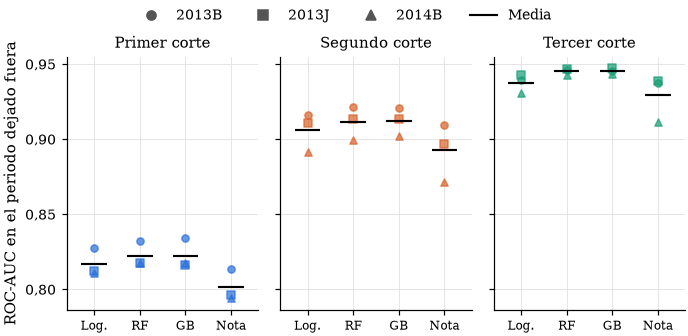

In [6]:
SHOW = ["lr_sel", "rf", "gb", "nota"]
short = {"lr_sel": "Log.", "rf": "RF", "gb": "GB", "nota": "Nota"}
markers = {"2013B": "o", "2013J": "s", "2014B": "^"}
fig, axes = plt.subplots(1, 3, figsize=(6.5, 3.0), sharey=True)
for ax, cut in zip(axes, c.CUTS):
    for i, m in enumerate(SHOW):
        r = table.loc[(cut, m)]
        for p in c.TRAIN_PERIODS:
            ax.scatter(i, r[p], marker=markers[p], s=22, color=c.CUT_COLORS[cut], alpha=0.7, zorder=3)
        ax.hlines(r["media"], i - 0.28, i + 0.28, color="black", lw=1.4, zorder=4)
    ax.set_xticks(range(len(SHOW)), [short[m] for m in SHOW], fontsize=8)
    ax.set_xlim(-0.6, len(SHOW) - 0.4)
    ax.set_title(c.CUT_NAMES[cut])
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
    c.comma_axis(ax, "y", 2)
axes[0].set_ylabel("ROC-AUC en el periodo dejado fuera")
handles = [plt.Line2D([], [], ls="", marker=markers[p], color="#555555", label=p) for p in c.TRAIN_PERIODS]
handles.append(plt.Line2D([], [], color="black", lw=1.4, label="Media"))
fig.legend(handles=handles, ncols=4, loc="upper center", bbox_to_anchor=(0.5, 1.07))
fig.tight_layout()
c.save_figure(fig, "resultados_validacion")
plt.show()

## 4. Diferencias pareadas y regla D9

Estadístico: la media de la ROC-AUC de cada periodo externo (la de la tabla), con bootstrap de
estudiantes dentro de cada clase (E13).

In [7]:
boot = {}
for cut in c.CUTS:
    d = data[cut]
    scores = {"lr_sel": oof[cut], "lr": res["lr"][cut]["oof"], "rf": res["rf"][cut]["oof"],
              "gb": res["gb"][cut]["oof"], "nota": c.baseline_score(d)}
    boot[cut] = c.bootstrap_auc_by_period(d[c.TARGET], scores, c.class_id(d), d["code_presentation"], reference="lr_sel")
pd.concat(boot, names=["corte", "modelo"])

auc  ic_inf  ic_sup    dif    dif_inf  dif_sup
corte modelo                                                  
first lr_sel  0.817   0.811   0.823  0.000  0.000e+00    0.000
      lr      0.822   0.816   0.828  0.005  3.331e-03    0.007
      rf      0.823   0.817   0.829  0.006  3.520e-03    0.007
      gb      0.823   0.816   0.828  0.006  3.734e-03    0.007
      nota    0.801   0.795   0.808 -0.016 -1.872e-02   -0.012
mid   lr_sel  0.906   0.901   0.911  0.000  0.000e+00    0.000
      lr      0.908   0.903   0.913  0.002  8.908e-04    0.003
      rf      0.912   0.907   0.916  0.005  4.184e-03    0.007
      gb      0.912   0.907   0.917  0.006  4.855e-03    0.007
      nota    0.893   0.887   0.898 -0.013 -1.617e-02   -0.011
last  lr_sel  0.938   0.934   0.941  0.000  0.000e+00    0.000
      lr      0.940   0.936   0.943  0.002  1.098e-03    0.003
      rf      0.945   0.942   0.949  0.008  6.494e-03    0.009
      gb      0.945   0.942   0.949  0.008  6.512e-03    0.009
      nota    0.929   0.925   0.934 -0.008 -1.040e-02   -0.006

In [8]:
d9 = []
for cut in c.CUTS:
    sd = table.loc[(cut, "lr_sel"), "desv."]
    for m in ["rf", "gb"]:
        b = boot[cut].loc[m]
        d9.append({"corte": cut, "modelo": m, "dif": b["dif"], "dif_inf": b["dif_inf"], "dif_sup": b["dif_sup"],
                   "desv. logística": sd, "(1) IC > 0": b["dif_inf"] > 0, "(2) dif > desv.": b["dif"] > sd})
d9 = pd.DataFrame(d9)
d9["cumple"] = d9["(1) IC > 0"] & d9["(2) dif > desv."]
d9

,corte,modelo,dif,dif_inf,dif_sup,desv. logística,(1) IC > 0,(2) dif > desv.,cumple
0,first,rf,0.006,0.004,0.007,0.009,True,False,False
1,first,gb,0.006,0.004,0.007,0.009,True,False,False
2,mid,rf,0.005,0.004,0.007,0.013,True,False,False
3,mid,gb,0.006,0.005,0.007,0.013,True,False,False
4,last,rf,0.008,0.006,0.009,0.006,True,True,True
5,last,gb,0.008,0.007,0.009,0.006,True,True,True


In [9]:
winners = [m for m in ["rf", "gb"] if d9.loc[d9["modelo"] == m, "cumple"].all()]
print("Modelos de árboles que cumplen D9 en los tres cortes:", winners or "ninguno")
print("Modelo final:", "regresión logística con selección de variables" if not winners else "PARAR Y PREGUNTAR A JOSE")

Modelos de árboles que cumplen D9 en los tres cortes: ninguno
Modelo final: regresión logística con selección de variables


In [10]:
# Frente a la regla de la nota (logística con selección − nota) y frente a la logística con todas
vs = pd.DataFrame({cut: {"lr_sel − nota": -boot[cut].loc["nota", "dif"],
                         "IC inf": -boot[cut].loc["nota", "dif_sup"], "IC sup": -boot[cut].loc["nota", "dif_inf"],
                         "lr (todas) − lr_sel": boot[cut].loc["lr", "dif"],
                         "IC inf ": boot[cut].loc["lr", "dif_inf"], "IC sup ": boot[cut].loc["lr", "dif_sup"]}
                   for cut in c.CUTS}).T
vs

,lr_sel − nota,IC inf,IC sup,lr (todas) − lr_sel,IC inf,IC sup
first,0.016,0.012,0.019,0.005,3.331e-03,0.007
mid,0.013,0.011,0.016,0.002,8.908e-04,0.003
last,0.008,0.006,0.010,0.002,1.098e-03,0.003


## 5. El umbral F2 en el periodo dejado fuera

In [11]:
thr_table = folds.groupby("corte")[["umbral", "sensibilidad", "precisión", "F2", "marcados (%)"]].agg(["mean", "std"]).reindex(c.CUTS)
thr_table

umbral        sensibilidad        precisión            F2        marcados (%)       
        mean    std         mean    std      mean    std   mean    std         mean    std
corte                                                                                     
first  0.212  0.049        0.930  0.010     0.527  0.038  0.806  0.023       77.548  2.041
mid    0.220  0.023        0.900  0.020     0.656  0.071  0.836  0.012       54.350  1.781
last   0.245  0.044        0.901  0.023     0.714  0.041  0.856  0.009       45.374  2.900

In [12]:
c.save_json({"table": table.reset_index().to_dict("records"), "folds": folds.drop(columns="variables").to_dict("records"),
             "variables": {p: v for p, v in folds.groupby("periodo fuera").first()["variables"].items()},
             "orders": {p: list(o.index) for p, o in orders.items()},
             "d9": d9.to_dict("records"), "winners": winners, "vs": vs.to_dict(),
             "umbral": thr_table.set_axis([f"{a} {b}" for a, b in thr_table.columns], axis=1).to_dict()},
            c.ARTIFACTS / "03_seleccion.json")

## Conclusiones

- **Orden de las variables** muy estable entre pliegues: `mean_score_with_zeros` (valor) primera
  siempre; luego su percentil, `last_score` (valor) y `recent_clicks_28d`; `repeated_course`,
  `clicks_per_active_day` y `pre_course_clicks`, últimas.
- **Selección**: la regla de un error típico elige k = 5, 4, 4 (el máximo estaba en 5, 5, 10),
  con C = 0,001, 0,001, 0,03. La grilla de C se cerró en 0,001 (E13).
- **ROC-AUC externa** de la logística con selección: 0,817 · 0,906 · 0,938; frente a la logística
  con todas, 0,005 · 0,002 · 0,002 menos (IC excluye el 0, pero menor que la desviación entre
  periodos): con 4–5 variables rinde de forma equivalente.
- **D9** (por periodo, E13): RF y GB la superan por 0,005–0,008; solo en el tercer corte supera
  a la desviación entre periodos. **Modelo final: regresión logística con selección (E14).**
- **Frente a la regla de la nota**: +0,016 · +0,013 · +0,008, con IC por encima de 0.
- **Umbral F2** en el periodo externo: sensibilidad 0,93 · 0,90 · 0,90, precisión 0,53 · 0,66 ·
  0,71; marca al 78 % · 54 % · 45 % de los estudiantes (prevalencia 32–46 %).